# World Models — VAE + MDN-RNN + Controller (Dream Training)

**Paper:** Ha, D., & Schmidhuber, J. (2018). *World Models.* [arXiv:1803.10122](https://arxiv.org/abs/1803.10122)

This notebook implements the three-module World Models architecture from scratch in PyTorch:

1. **V ("Vision"):** a variational autoencoder that compresses each 64x64 frame into a 32-dimensional latent vector z.
2. **M ("Memory"):** an MDN-RNN that predicts the distribution of the next latent z, and here also the reward.
3. **C ("Controller"):** a tiny linear policy on [z, h], trained with a simple evolution strategy **inside the dream** generated by M, then tested in the real environment.

The paper trains its controller inside the dream for the VizDoom: Take Cover task (its CarRacing controller was trained in the real environment). Here a small 2D **PointMassNav** task (NumPy only) stands in for both, so the whole pipeline runs on a CPU in a few minutes. The Summary at the end says what this run found.

## 1. Setup & Imports


In [1]:
import atexit
import math
import os
import random
import shutil
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Show figures as JPEG at a modest resolution to keep the saved notebook small
set_matplotlib_formats('jpeg')
plt.rcParams['figure.dpi'] = 80

# On Kaggle (detected from its environment), keep a copy of this notebook with its outputs when
# the kernel exits, so `kaggle kernels output` can download the executed version
if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ:
    atexit.register(lambda: os.path.exists('__notebook__.ipynb')
                    and shutil.copy('__notebook__.ipynb', 'executed_solution.ipynb'))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# One CPU thread and deterministic kernels, so results do not depend on the machine's core count
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

device = torch.device('cpu')
print(f"Device: {device}")

Device: cpu


## 2. Toy Environment: PointMassNav

A minimal 2D continuous-control navigation task rendered as 64x64 grayscale images.

- **State:** (x, y) position in [-1, 1]^2
- **Action:** continuous (dx, dy) velocity in [-1, 1]
- **Observation:** 64x64 grayscale image (agent = bright dot, target = cross)
- **Reward:** -distance to target per step; +10 on reaching target (within 0.1)


Observation shape: (64, 64), range: [0.00, 1.00]
Agent pos: [0.07810161 0.34430298], Target: [0.1644214  0.07181309], Distance: 0.286


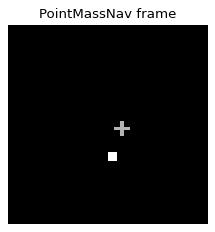

In [2]:
class PointMassNav:
    '''Minimal 2D navigation env that renders 64x64 grayscale frames.'''
    def __init__(self, seed=None):
        self.size = 64
        self.rng = np.random.RandomState(seed)
        self.pos = None
        self.target = None
        self.steps = 0
        self.max_steps = 100

    def reset(self):
        self.pos = self.rng.uniform(-0.8, 0.8, size=2).astype(np.float32)
        self.target = self.rng.uniform(-0.8, 0.8, size=2).astype(np.float32)
        self.steps = 0
        return self._render()

    def _render(self):
        frame = np.zeros((self.size, self.size), dtype=np.float32)
        ax, ay = self._to_pixel(self.pos)
        for dx in range(-1, 2):
            for dy in range(-1, 2):
                px, py = ax + dx, ay + dy
                if 0 <= px < self.size and 0 <= py < self.size:
                    frame[py, px] = 1.0
        tx, ty = self._to_pixel(self.target)
        for d in range(-2, 3):
            px, py = tx + d, ty
            if 0 <= px < self.size and 0 <= py < self.size:
                frame[py, px] = 0.7
            px, py = tx, ty + d
            if 0 <= px < self.size and 0 <= py < self.size:
                frame[py, px] = 0.7
        return frame

    def _to_pixel(self, coord):
        x = int((coord[0] + 1.0) / 2.0 * (self.size - 1))
        y = int((coord[1] + 1.0) / 2.0 * (self.size - 1))
        return x, y

    def step(self, action):
        action = np.clip(action, -1.0, 1.0).astype(np.float32)
        self.pos = np.clip(self.pos + action * 0.1, -1.0, 1.0)
        self.steps += 1
        dist = np.linalg.norm(self.pos - self.target)
        done = dist < 0.1 or self.steps >= self.max_steps
        reward = -dist + (10.0 if dist < 0.1 else 0.0)
        return self._render(), float(reward), done, {'dist': float(dist)}

env = PointMassNav(seed=0)
obs = env.reset()
print(f"Observation shape: {obs.shape}, range: [{obs.min():.2f}, {obs.max():.2f}]")
print(f"Agent pos: {env.pos}, Target: {env.target}, Distance: {np.linalg.norm(env.pos - env.target):.3f}")

fig, ax = plt.subplots(1, 1, figsize=(3, 3))
ax.imshow(obs, cmap='gray', vmin=0, vmax=1)
ax.set_title('PointMassNav frame')
ax.axis('off')
plt.tight_layout()
plt.show()


## 3. Collect Random Rollouts

We run random-policy episodes to collect observation sequences for training
the VAE and MDN-RNN. The paper uses the same approach: collect first,
learn representations second.


In [3]:
def collect_rollouts(env, n_episodes=50, max_steps=100):
    all_frames = []
    all_actions = []
    all_rewards = []
    for ep in range(n_episodes):
        obs = env.reset()
        frames = [obs]
        actions = []
        rewards = []
        for t in range(max_steps):
            a = env.rng.uniform(-1, 1, size=2).astype(np.float32)
            obs, r, done, info = env.step(a)
            actions.append(a)
            rewards.append(r)
            frames.append(obs)
            if done:
                break
        all_frames.append(np.array(frames))
        all_actions.append(np.array(actions))
        all_rewards.append(np.array(rewards))
    return all_frames, all_actions, all_rewards

env_collect = PointMassNav(seed=SEED)
all_frames, all_actions, all_rewards = collect_rollouts(env_collect, n_episodes=50, max_steps=100)
total_frames = sum(len(f) for f in all_frames)
print(f"Collected {len(all_frames)} episodes, {total_frames} frames total")
print(f"Frame shape: {all_frames[0].shape}, Action shape: {all_actions[0].shape}")


Collected 50 episodes, 4749 frames total
Frame shape: (101, 64, 64), Action shape: (100, 2)


## 4. VAE Module ("V")

A convolutional variational autoencoder that compresses 64x64 grayscale frames
into a 32-dimensional latent vector. Trained on all collected frames.


In [4]:
class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.latent_dim = latent_dim
        # Encoder: 64x64x1 -> conv layers -> mu, logvar
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),   # 64 -> 32
            nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1),   # 32 -> 16
            nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1),  # 16 -> 8
            nn.ReLU(),
            nn.Flatten(),
        )
        self.fc_mu = nn.Linear(128 * 8 * 8, latent_dim)
        self.fc_logvar = nn.Linear(128 * 8 * 8, latent_dim)
        # Decoder: z -> deconv -> 64x64x1
        self.dec_fc = nn.Linear(latent_dim, 128 * 8 * 8)
        self.dec_deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 8 -> 16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),    # 16 -> 32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1),     # 32 -> 64
        )

    def encode(self, x):
        h = self.enc_conv(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return z, mu, logvar

    def decode(self, z):
        h = self.dec_fc(z).view(-1, 128, 8, 8)
        return self.dec_deconv(h)

    def forward(self, x):
        z, mu, logvar = self.encode(x)
        recon = self.decode(z)
        return recon, mu, logvar, z

LATENT_DIM = 32
vae = VAE(latent_dim=LATENT_DIM).to(device)
print(f"VAE parameters: {sum(p.numel() for p in vae.parameters())}")


VAE parameters: 1123713


### Train the VAE


In [5]:
def vae_loss(recon, x, mu, logvar, beta=1.0):
    recon_loss = F.binary_cross_entropy_with_logits(recon, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + beta * kl, recon_loss.item(), kl.item()

all_frame_arr = np.concatenate(all_frames, axis=0)
all_frame_tensor = torch.FloatTensor(all_frame_arr).unsqueeze(1).to(device)

vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
EPOCHS_VAE = 30
BATCH_SIZE = 128
N = all_frame_tensor.shape[0]
vae_losses = []

for epoch in range(EPOCHS_VAE):
    perm = torch.randperm(N)
    epoch_loss = 0
    for i in range(0, N, BATCH_SIZE):
        idx = perm[i:i+BATCH_SIZE]
        batch = all_frame_tensor[idx]
        recon, mu, logvar, z = vae(batch)
        loss, rl, kl = vae_loss(recon, batch, mu, logvar, beta=1.0)
        vae_optimizer.zero_grad()
        loss.backward()
        vae_optimizer.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / N
    vae_losses.append(avg_loss)
    if (epoch + 1) % 10 == 0:
        print(f"VAE Epoch {epoch+1}/{EPOCHS_VAE}, Loss/frame: {avg_loss:.4f}")

print(f"VAE training complete. Final loss: {vae_losses[-1]:.4f}")


VAE Epoch 10/30, Loss/frame: 98.9596


VAE Epoch 20/30, Loss/frame: 57.5643


VAE Epoch 30/30, Loss/frame: 42.9349
VAE training complete. Final loss: 42.9349


### VAE Reconstruction Quality


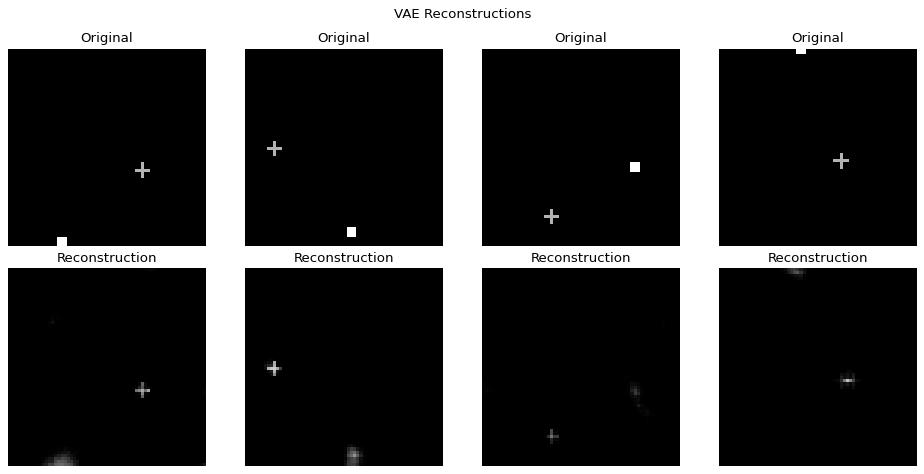

Sample latent z shape: torch.Size([4, 32])


In [6]:
vae.eval()
with torch.no_grad():
    test_idx = np.random.choice(N, 4, replace=False)
    test_batch = all_frame_tensor[test_idx]
    recon, mu, logvar, z = vae(test_batch)
    recon_sigmoid = torch.sigmoid(recon)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(test_batch[i, 0].cpu().numpy(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title('Original')
    axes[0, i].axis('off')
    axes[1, i].imshow(recon_sigmoid[i, 0].cpu().numpy(), cmap='gray', vmin=0, vmax=1)
    axes[1, i].set_title('Reconstruction')
    axes[1, i].axis('off')
plt.suptitle('VAE Reconstructions')
plt.tight_layout()
plt.show()
print(f"Sample latent z shape: {z.shape}")


## 5. MDN-RNN Module ("M")

An LSTM that reads (z_t, a_t) and outputs:
- the distribution of the next latent z_{t+1} as a mixture of K = 5 diagonal Gaussians (a mixture density network), and
- a prediction of the reward for that step.

In the paper, M for CarRacing only models the next z, and M for VizDoom also predicts whether the agent dies (Section 4.2). A dream needs some reward signal, so here M predicts the reward instead; the paper's Section 5 discusses M models that also predict the reward.

In [7]:
N_MIXTURES = 5
ACTION_DIM = 2
HIDDEN_DIM = 128

class MDNRNN(nn.Module):
    def __init__(self, latent_dim=32, action_dim=2, hidden_dim=128, n_mixtures=5):
        super().__init__()
        self.latent_dim = latent_dim
        self.action_dim = action_dim
        self.hidden_dim = hidden_dim
        self.n_mixtures = n_mixtures
        self.lstm = nn.LSTM(latent_dim + action_dim, hidden_dim, batch_first=True)
        # MDN output: K * (2*latent + 1) = K mixture logits + K*latent means + K*latent log-stds
        self.fc = nn.Linear(hidden_dim, n_mixtures * (2 * latent_dim + 1))
        # Reward head: the reward received for taking a_t in z_t
        self.fc_reward = nn.Linear(hidden_dim, 1)

    def forward(self, z_seq, a_seq, hidden=None):
        x = torch.cat([z_seq, a_seq], dim=-1)
        out, hidden = self.lstm(x, hidden)
        return self.fc(out), self.fc_reward(out).squeeze(-1), hidden

    def parse_mdn_params(self, params):
        B, T, _ = params.shape
        K = self.n_mixtures
        lat = self.latent_dim
        pi_raw = params[..., :K]
        mu = params[..., K:K + K * lat]
        log_std = params[..., K + K * lat:]
        pi = F.softmax(pi_raw, dim=-1)
        mu = mu.view(B, T, K, lat)
        log_std = log_std.view(B, T, K, lat)
        log_std = torch.clamp(log_std, min=-5.0, max=2.0)
        return pi, mu, log_std

def mdn_loss_fn(pi, mu, log_std, target_z, mask):
    '''Negative log-likelihood of target_z under the mixture, averaged over valid (unpadded) steps.'''
    target_exp = target_z.unsqueeze(2)
    var = torch.exp(log_std) ** 2
    log_prob = -0.5 * ((target_exp - mu) ** 2 / var + 2 * log_std + math.log(2 * math.pi))
    log_prob = log_prob.sum(dim=-1)
    log_mix_prob = torch.log(pi + 1e-8) + log_prob
    nll = -torch.logsumexp(log_mix_prob, dim=-1)
    return (nll * mask).sum() / mask.sum()

mdnrnn = MDNRNN(latent_dim=LATENT_DIM, action_dim=ACTION_DIM, hidden_dim=HIDDEN_DIM,
                n_mixtures=N_MIXTURES).to(device)
print(f"MDN-RNN parameters: {sum(p.numel() for p in mdnrnn.parameters()):,}")

MDN-RNN parameters: 126,022


### Prepare sequence data and train MDN-RNN

Each frame is encoded to its VAE mean μ, and M is trained on whole episodes (padded to the same length, with a mask), so the LSTM carries its hidden state through time as in the paper.

In [8]:
def encode_mu(frames):
    '''VAE mean for a stack of frames (N, 64, 64) -> (N, latent_dim).'''
    with torch.no_grad():
        _, mu, _ = vae.encode(torch.FloatTensor(np.asarray(frames)).reshape(-1, 1, 64, 64).to(device))
    return mu

def prepare_sequences(all_frames, all_actions, all_rewards):
    vae.eval()
    n, T = len(all_actions), max(len(a) for a in all_actions)
    Z = torch.zeros(n, T, LATENT_DIM)
    Z_next = torch.zeros(n, T, LATENT_DIM)
    A = torch.zeros(n, T, ACTION_DIM)
    R = torch.zeros(n, T)
    M = torch.zeros(n, T)
    for i, (frames, actions, rewards) in enumerate(zip(all_frames, all_actions, all_rewards)):
        mu = encode_mu(frames)
        L = len(actions)
        Z[i, :L], Z_next[i, :L] = mu[:-1], mu[1:]
        A[i, :L] = torch.FloatTensor(actions)
        R[i, :L] = torch.FloatTensor(rewards)
        M[i, :L] = 1.0
    return Z, A, Z_next, R, M

Z_seq, A_seq, Z_next_seq, R_seq, M_seq = prepare_sequences(all_frames, all_actions, all_rewards)
print(f"Sequences: {Z_seq.shape[0]} episodes x {Z_seq.shape[1]} steps, {int(M_seq.sum())} valid steps")

mdn_optimizer = torch.optim.Adam(mdnrnn.parameters(), lr=1e-3)
EPOCHS_MDN = 200
BATCH_EPISODES = 10
REWARD_LOSS_WEIGHT = 10.0
mdn_losses, reward_losses = [], []
mdn_rng = np.random.RandomState(SEED)

for epoch in range(EPOCHS_MDN):
    perm = mdn_rng.permutation(Z_seq.shape[0])
    ep_nll, ep_rmse, count = 0.0, 0.0, 0
    for i in range(0, len(perm), BATCH_EPISODES):
        idx = torch.as_tensor(perm[i:i + BATCH_EPISODES])
        params, r_pred, _ = mdnrnn(Z_seq[idx], A_seq[idx])
        pi, mu, log_std = mdnrnn.parse_mdn_params(params)
        nll = mdn_loss_fn(pi, mu, log_std, Z_next_seq[idx], M_seq[idx])
        r_mse = (((r_pred - R_seq[idx]) ** 2) * M_seq[idx]).sum() / M_seq[idx].sum()
        loss = nll + REWARD_LOSS_WEIGHT * r_mse
        mdn_optimizer.zero_grad()
        loss.backward()
        mdn_optimizer.step()
        ep_nll += nll.item()
        ep_rmse += r_mse.item()
        count += 1
    mdn_losses.append(ep_nll / count)
    reward_losses.append(ep_rmse / count)
    if (epoch + 1) % 40 == 0:
        print(f"MDN-RNN Epoch {epoch+1}/{EPOCHS_MDN}, NLL: {mdn_losses[-1]:.3f}, reward MSE: {reward_losses[-1]:.4f}")

print(f"MDN-RNN training complete. Final NLL: {mdn_losses[-1]:.3f}, reward MSE: {reward_losses[-1]:.4f}")
print(f"For scale: variance of the real per-step rewards = {R_seq[M_seq > 0].var().item():.4f}")

Sequences: 50 episodes x 100 steps, 4699 valid steps


MDN-RNN Epoch 40/200, NLL: 10.232, reward MSE: 0.1454


MDN-RNN Epoch 80/200, NLL: 3.441, reward MSE: 0.1235


MDN-RNN Epoch 120/200, NLL: -0.288, reward MSE: 0.1090


MDN-RNN Epoch 160/200, NLL: -2.674, reward MSE: 0.1049


MDN-RNN Epoch 200/200, NLL: -5.537, reward MSE: 0.0990
MDN-RNN training complete. Final NLL: -5.537, reward MSE: 0.0990
For scale: variance of the real per-step rewards = 0.2920


## 6. Controller Module ("C")

A tiny linear policy: a_t = tanh(W [z_t, h_t] + b), with 322 parameters. As in the paper, C sees both the latent z_t and M's hidden state h_t.

In [9]:
class Controller(nn.Module):
    def __init__(self, latent_dim=32, hidden_dim=128, action_dim=2):
        super().__init__()
        self.fc = nn.Linear(latent_dim + hidden_dim, action_dim)

    def forward(self, z, h):
        x = torch.cat([z, h], dim=-1)
        return torch.tanh(self.fc(x))

controller = Controller(latent_dim=LATENT_DIM, hidden_dim=HIDDEN_DIM, action_dim=ACTION_DIM).to(device)
print(f"Controller parameters: {sum(p.numel() for p in controller.parameters())}")


Controller parameters: 322


## 7. Dream Environment

The dream replaces the real simulator: M generates the next latent and the reward, and the controller acts entirely in latent space. Each dream episode starts from the latent of a real frame from the collected rollouts. A temperature τ flattens the mixture weights and widens the Gaussians; the paper found that a higher τ makes the dream harder to exploit (Section 4.5). Many dream episodes run in parallel as one batch.

In [10]:
class DreamEnv:
    '''A batch of hallucinated episodes, run entirely by M.'''
    def __init__(self, mdnrnn, start_latents, temperature=1.0, max_steps=100, seed=SEED):
        self.mdnrnn = mdnrnn
        self.start_latents = start_latents
        self.temperature = temperature
        self.max_steps = max_steps
        self.gen = torch.Generator().manual_seed(seed)

    def reset(self, start_idx):
        self.z = self.start_latents[torch.as_tensor(start_idx)].clone()
        self.hidden = None
        self.steps = 0
        return self.z, torch.zeros(len(start_idx), HIDDEN_DIM)

    def step(self, action):
        params, r_pred, self.hidden = self.mdnrnn(self.z.unsqueeze(1), action.unsqueeze(1), self.hidden)
        pi, mu, log_std = self.mdnrnn.parse_mdn_params(params)
        pi, mu, log_std = pi[:, 0], mu[:, 0], log_std[:, 0]
        B = pi.shape[0]
        # Temperature: flatten the mixture weights and widen each Gaussian
        probs = F.softmax(torch.log(pi + 1e-8) / self.temperature, dim=-1)
        k = torch.multinomial(probs, 1, generator=self.gen).squeeze(1)
        mu_k = mu[torch.arange(B), k]
        std_k = torch.exp(log_std[torch.arange(B), k]) * math.sqrt(self.temperature)
        self.z = mu_k + std_k * torch.randn(mu_k.shape, generator=self.gen)
        self.steps += 1
        done = self.steps >= self.max_steps
        return (self.z, self.hidden[0][0]), r_pred[:, 0], done

# Start states: the latents of all collected real frames
start_latents = encode_mu(np.concatenate(all_frames, axis=0))
TEMPERATURE = 1.15
dream = DreamEnv(mdnrnn, start_latents, temperature=TEMPERATURE, max_steps=100)

with torch.no_grad():
    z0, h0 = dream.reset([0])
    (z1, h1), r1, d1 = dream.step(torch.zeros(1, ACTION_DIM))
print(f"Start states: {start_latents.shape[0]}, dream z: {tuple(z1.shape)}, h: {tuple(h1.shape)}")
print(f"One dream step: predicted reward = {r1.item():.3f}, done = {d1}")

Start states: 4749, dream z: (1, 32), h: (1, 128)
One dream step: predicted reward = -0.550, done = False


## 8. Train Controller with Evolution Strategy

A simple evolution strategy instead of the paper's CMA-ES. Each generation samples a population of parameter vectors around the current mean, scores each one by its average predicted reward over the same set of dream episodes, and moves the mean towards the better ones using centered rank weights (best +0.5, worst −0.5, summing to zero). The whole population runs in the dream as one batch.

In [11]:
N_PARAMS = controller.fc.weight.numel() + controller.fc.bias.numel()
W_SIZE = controller.fc.weight.numel()
print(f"Controller parameter count: {N_PARAMS}")

def batched_actions(params, z, h, n_episodes):
    '''params (P, N_PARAMS); z, h (P * n_episodes, .) -> actions (P * n_episodes, ACTION_DIM).'''
    P = params.shape[0]
    W = params[:, :W_SIZE].view(P, ACTION_DIM, LATENT_DIM + HIDDEN_DIM)
    b = params[:, W_SIZE:]
    x = torch.cat([z, h], dim=-1).view(P, n_episodes, -1)
    a = torch.tanh(torch.einsum('pei,poi->peo', x, W) + b[:, None, :])
    return a.reshape(P * n_episodes, ACTION_DIM)

def evaluate_in_dream(params, dream, start_idx):
    '''Average predicted dream return of each parameter vector over the same start states.'''
    P, E = params.shape[0], len(start_idx)
    z, h = dream.reset(np.tile(start_idx, P))
    total = torch.zeros(P * E)
    with torch.no_grad():
        for t in range(dream.max_steps):
            a = batched_actions(params, z, h, E)
            (z, h), r, done = dream.step(a)
            total += r
    return total.view(P, E).mean(dim=1).numpy()

POP_SIZE = 64
N_GENERATIONS = 60
N_DREAM_EPISODES = 16
SIGMA = 0.1
LEARNING_RATE = 0.5

es_rng = np.random.RandomState(SEED)
mean_params = np.zeros(N_PARAMS)
es_history = []
start_time = time.time()

for gen in range(N_GENERATIONS):
    noise = es_rng.randn(POP_SIZE, N_PARAMS)
    pop = mean_params + SIGMA * noise
    start_idx = es_rng.randint(0, len(start_latents), size=N_DREAM_EPISODES)
    rewards = evaluate_in_dream(torch.FloatTensor(pop), dream, start_idx)
    # Centered rank weights: no division, so no risk of dividing by zero
    ranks = np.argsort(np.argsort(rewards))          # 0 = worst, POP_SIZE - 1 = best
    weights = ranks / (POP_SIZE - 1) - 0.5
    mean_params = mean_params + LEARNING_RATE / POP_SIZE * (weights @ noise)
    mean_reward = evaluate_in_dream(torch.FloatTensor(mean_params[None]), dream, start_idx)[0]
    es_history.append((rewards.mean(), rewards.max(), mean_reward))
    if (gen + 1) % 10 == 0:
        print(f"Gen {gen+1}/{N_GENERATIONS}: population mean {rewards.mean():.2f}, "
              f"best {rewards.max():.2f}, mean controller {mean_reward:.2f}")

controller.fc.weight.data = torch.FloatTensor(mean_params[:W_SIZE]).view_as(controller.fc.weight)
controller.fc.bias.data = torch.FloatTensor(mean_params[W_SIZE:])
print(f"ES complete in {time.time() - start_time:.0f} s. "
      f"Dream return of the final mean controller: {es_history[-1][2]:.2f}")

Controller parameter count: 322


Gen 10/60: population mean -51.91, best -39.02, mean controller -47.55


Gen 20/60: population mean -42.04, best -31.62, mean controller -42.10


Gen 30/60: population mean -38.23, best -29.81, mean controller -33.87


Gen 40/60: population mean -40.28, best -31.28, mean controller -38.54


Gen 50/60: population mean -38.46, best -30.35, mean controller -38.96


Gen 60/60: population mean -36.97, best -29.60, mean controller -33.85
ES complete in 82 s. Dream return of the final mean controller: -33.85


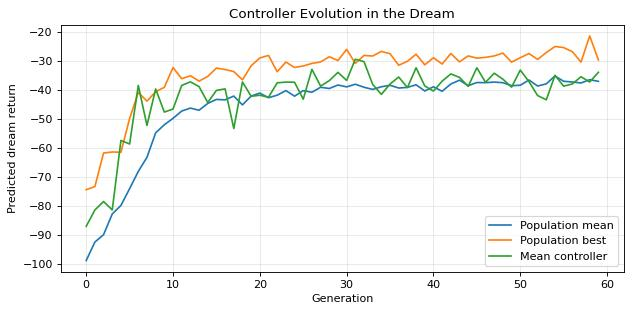

In [12]:
hist_arr = np.array(es_history)
plt.figure(figsize=(8, 4))
plt.plot(hist_arr[:, 0], label='Population mean')
plt.plot(hist_arr[:, 1], label='Population best')
plt.plot(hist_arr[:, 2], label='Mean controller')
plt.xlabel('Generation')
plt.ylabel('Predicted dream return')
plt.title('Controller Evolution in the Dream')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Transfer to the Real Environment

The dream-trained controller now acts in the real PointMassNav. At each step the real frame is encoded by V, and M is run on (z_t, a_t) with its hidden state carried along to give h_t. We test on 20 new episodes and compare with two baselines on the same episodes: a randomly initialised controller, and uniformly random actions.

In [13]:
def run_real_episode(policy, seed, record=False):
    '''Run one real episode. policy(z, h) -> action tensor (1, ACTION_DIM).'''
    env = PointMassNav(seed=seed)
    obs = env.reset()
    hidden, h = None, torch.zeros(1, HIDDEN_DIM)
    positions, total = [env.pos.copy()], 0.0
    start_dist = float(np.linalg.norm(env.pos - env.target))
    for t in range(env.max_steps):
        z = encode_mu(obs)
        with torch.no_grad():
            a = policy(z, h)
            _, _, hidden = mdnrnn(z.unsqueeze(1), a.unsqueeze(1), hidden)
        h = hidden[0][0]
        obs, r, done, info = env.step(a.squeeze(0).numpy())
        total += r
        positions.append(env.pos.copy())
        if done:
            break
    result = {'reward': total, 'final_dist': info['dist'], 'start_dist': start_dist,
              'reached': info['dist'] < 0.1, 'steps': env.steps}
    if record:
        result.update(positions=np.array(positions), target=env.target.copy())
    return result

def evaluate_real_env(policy, n_episodes=20, seed_offset=100):
    results = [run_real_episode(policy, seed_offset + ep) for ep in range(n_episodes)]
    return {k: np.array([r[k] for r in results]) for k in results[0]}

controller.eval()
real_dream = evaluate_real_env(lambda z, h: controller(z, h))
print("Real env (dream-trained controller):")
print(f"  Mean reward: {real_dream['reward'].mean():.3f} +/- {real_dream['reward'].std():.3f}")
print(f"  Mean final distance: {real_dream['final_dist'].mean():.3f} (mean start distance {real_dream['start_dist'].mean():.3f})")
print(f"  Reached the target: {int(real_dream['reached'].sum())}/{len(real_dream['reached'])} episodes")

Real env (dream-trained controller):
  Mean reward: -133.536 +/- 38.531
  Mean final distance: 1.396 (mean start distance 0.932)
  Reached the target: 0/20 episodes


## 10. Comparison: Baselines vs Dream-Trained Controller

In [14]:
random_controller = Controller(latent_dim=LATENT_DIM, hidden_dim=HIDDEN_DIM, action_dim=ACTION_DIM).to(device)
real_init = evaluate_real_env(lambda z, h: random_controller(z, h))
action_rng = torch.Generator().manual_seed(SEED)
real_uniform = evaluate_real_env(lambda z, h: torch.rand(1, ACTION_DIM, generator=action_rng) * 2 - 1)

rows = [('Random-init controller', real_init), ('Uniform random actions', real_uniform),
        ('Dream-trained controller', real_dream)]
print(f"{'Policy':<26} {'Mean reward':>12} {'Final dist':>11} {'Reached':>8}")
print('-' * 60)
for name, r in rows:
    print(f"{name:<26} {r['reward'].mean():>12.2f} {r['final_dist'].mean():>11.3f} "
          f"{int(r['reached'].sum()):>5}/{len(r['reached'])}")
print(f"\nDream-trained minus random-init controller (mean reward): "
      f"{real_dream['reward'].mean() - real_init['reward'].mean():+.2f}")
print(f"Dream-trained minus uniform random actions (mean reward): "
      f"{real_dream['reward'].mean() - real_uniform['reward'].mean():+.2f}")

Policy                      Mean reward  Final dist  Reached
------------------------------------------------------------
Random-init controller          -111.79       1.200     0/20
Uniform random actions          -101.57       1.049     0/20
Dream-trained controller        -133.54       1.396     0/20

Dream-trained minus random-init controller (mean reward): -21.75
Dream-trained minus uniform random actions (mean reward): -31.96


### What do V's latents know about the positions?

The controller and M only ever see z. To check how much z says about the task, we fit a linear map from z to the agent and target positions on 300 fresh frames and measure R² on 100 more (1 = perfect, 0 = no better than guessing the average). We also compare the controller's predicted return in the dream with its actual return in the real environment.

In [15]:
probe_env = PointMassNav(seed=7)
Zp, Yp = [], []
for i in range(400):
    obs = probe_env.reset()
    Zp.append(encode_mu(obs)[0].numpy())
    Yp.append(np.r_[probe_env.pos, probe_env.target])
Zp, Yp = np.array(Zp), np.array(Yp)
Xa = np.c_[Zp, np.ones(len(Zp))]
w = np.linalg.lstsq(Xa[:300], Yp[:300], rcond=None)[0]
pred = Xa[300:] @ w
r2 = 1 - ((pred - Yp[300:]) ** 2).sum(0) / ((Yp[300:] - Yp[300:].mean(0)) ** 2).sum(0)
for name, v in zip(['agent x', 'agent y', 'target x', 'target y'], r2):
    print(f"Linear-probe R^2 for {name}: {v:.2f}")

print(f"\nDream-trained controller, predicted return in the dream: {es_history[-1][2]:.1f}")
print(f"Dream-trained controller, actual mean return in the real env: {real_dream['reward'].mean():.1f}")


Linear-probe R^2 for agent x: 0.09
Linear-probe R^2 for agent y: 0.14
Linear-probe R^2 for target x: 0.17
Linear-probe R^2 for target y: 0.13

Dream-trained controller, predicted return in the dream: -33.9
Dream-trained controller, actual mean return in the real env: -133.5


## 11. Visualize Trajectories


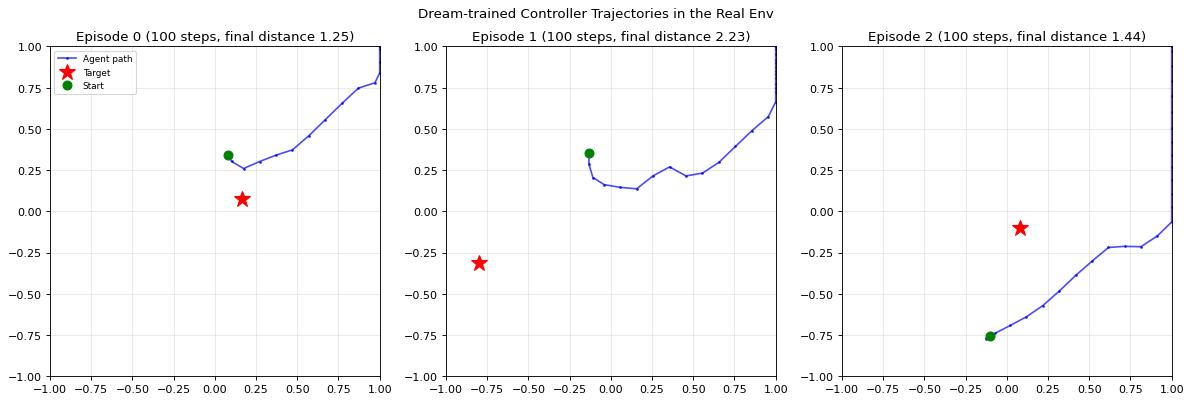

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, seed in enumerate([0, 1, 2]):
    ep = run_real_episode(lambda z, h: controller(z, h), seed, record=True)
    pos, target = ep['positions'], ep['target']
    axes[i].plot(pos[:, 0], pos[:, 1], 'b.-', markersize=3, alpha=0.7, label='Agent path')
    axes[i].plot(target[0], target[1], 'r*', markersize=15, label='Target')
    axes[i].plot(pos[0, 0], pos[0, 1], 'go', markersize=8, label='Start')
    axes[i].set_xlim(-1, 1)
    axes[i].set_ylim(-1, 1)
    axes[i].set_title(f"Episode {seed} ({ep['steps']} steps, final distance {ep['final_dist']:.2f})")
    axes[i].set_aspect('equal')
    axes[i].grid(True, alpha=0.3)
    if i == 0:
        axes[i].legend(fontsize=8)
plt.suptitle('Dream-trained Controller Trajectories in the Real Env')
plt.tight_layout()
plt.show()

## 12. Summary

### What the run above shows

**The dream-trained controller lost to both random baselines in the real environment.** Over the same 20 test episodes:

| Policy | Mean reward | Mean final distance | Reached target |
|---|---|---|---|
| Random-init controller | −111.8 | 1.200 | 0/20 |
| Uniform random actions | −101.6 | 1.049 | 0/20 |
| Dream-trained controller | −133.5 | 1.396 | 0/20 |

The episodes started 0.932 from the target on average, so the dream-trained controller ended further away than it started. The trajectory plots show why: it drives towards the top-right wall whatever the target's position.

What happened in each module:

- **V (1,123,713 parameters)** got its loss per frame down from 99.0 to 42.9 in 30 epochs. The reconstructions keep the target's cross but blur or misplace the small agent square. A linear probe recovers the positions from z with R² of only 0.09 (agent x), 0.14 (agent y), 0.17 (target x) and 0.13 (target y).
- **M (126,022 parameters)** brought its next-z NLL down to −5.5 and its reward MSE to 0.099, against a reward variance of 0.292. So it explains about two-thirds of the reward's variance, but not from a clear picture of where the agent and target are.
- **C (322 parameters)** did learn inside the dream: the mean controller's predicted return rose from −47.6 at generation 10 to −33.9 at generation 60. In the real environment, the same controller's return was −133.5.

That gap is the failure the paper calls "cheating the world model" (Section 4.5): the controller found behaviour that M scores well but that does not work in reality. Here the root cause is that V's latents carry little information about the positions, so neither M nor C can know where the target is. The paper's own dream training (VizDoom) used 10,000 rollouts and a much larger V and M; this notebook uses 50 rollouts, so it shows the pipeline and its main pitfall rather than the paper's successful transfer. An earlier version of this notebook claimed the controller beat a random baseline, which its own outputs contradicted; its evolution step also never moved the mean reward.
